# 01 – Data preparation

This notebook prepares everything the training notebook needs:

1. downloads the multi-label AID dataset and the original AID dataset,
2. recovers the scene label of every multi-label image by matching it to its AID original,
3. creates the train / validation / test split,
4. caches all 10,000 images at 224×224,
5. produces the dataset statistics and figures used in the report.

## 1. Setup

Imports, paths and constants. `SPLIT_SEED` fixes the data split; it is independent of the training seeds.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from huggingface_hub import snapshot_download
from PIL import Image
from tqdm.auto import tqdm

from aidml import PROCESSED_DIR, RESULTS_DIR, compute_metrics, load_data, scene_object_table, split_indices

RAW_DIR = Path("data/raw")
FIGURE_DIR = Path("figures")
for folder in [RAW_DIR, PROCESSED_DIR, RESULTS_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SPLIT_SEED = 0
IMAGE_SIZE = 224
THUMB_SIZE = 32

## 2. Download the multi-label AID dataset

The 3,000 images annotated by Hua et al. with 17 object labels
([jonathan-roberts1/AID_MultiLabel](https://huggingface.co/datasets/jonathan-roberts1/AID_MultiLabel)).
This release contains only the images and the object labels: no file names and no scene labels.

In [2]:
multilabel = load_dataset("jonathan-roberts1/AID_MultiLabel", split="train", cache_dir=RAW_DIR / "hf_cache")
all_object_names = multilabel.features["label"].feature.names
print(len(multilabel), "images")
print(all_object_names)

3000 images
['airplane', 'bare soil', 'buildings', 'cars', 'chaparral', 'court', 'dock', 'field', 'grass', 'mobile home', 'pavement', 'sand', 'sea', 'ship', 'tanks', 'trees', 'water']


## 3. Download the original AID dataset

The 10,000 single-label images, stored in one folder per scene
([blanchon/AID](https://huggingface.co/datasets/blanchon/AID), about 2.7 GB).
Files that are already on disk are not downloaded again.

In [3]:
snapshot_download("blanchon/AID", repo_type="dataset", local_dir=RAW_DIR / "AID", allow_patterns="data/*")

image_types = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
aid_files = sorted(p for p in (RAW_DIR / "AID" / "data").rglob("*") if p.suffix.lower() in image_types)
aid = pd.DataFrame({"file": [str(p) for p in aid_files], "scene": [p.parent.name for p in aid_files]})
scene_names = sorted(aid["scene"].unique())
aid["scene_id"] = aid["scene"].map({name: i for i, name in enumerate(scene_names)})
print(len(aid), "images,", len(scene_names), "scenes")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10000 files:   0%|          | 0/10000 [00:00<?, ?it/s]

10000 images, 30 scenes


Number of images per scene. AID has between 220 and 420 images per scene.

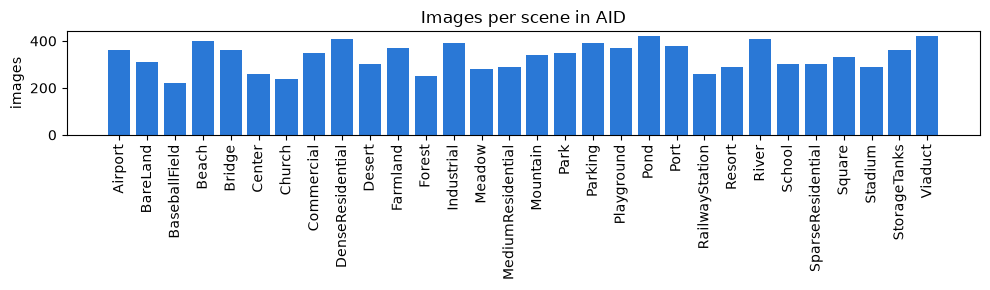

In [4]:
counts = aid["scene"].value_counts().sort_index()
plt.figure(figsize=(10, 3))
plt.bar(counts.index, counts.values, color="#2a78d6")
plt.xticks(rotation=90)
plt.ylabel("images")
plt.title("Images per scene in AID")
plt.tight_layout()
plt.show()

## 4. Resize every image

Each image is decoded once. We keep a 224×224 RGB copy for training and a 32×32 grayscale thumbnail for matching.
Both datasets go through the same function, so two identical images give identical thumbnails.
This step takes a few minutes.

In [5]:
def resize(image):
    image = image.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR)
    thumb = image.convert("L").resize((THUMB_SIZE, THUMB_SIZE), Image.BILINEAR)
    return np.asarray(image), np.asarray(thumb, dtype=np.float32).ravel() / 255


aid_images = np.zeros((len(aid), IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
aid_thumbs = np.zeros((len(aid), THUMB_SIZE * THUMB_SIZE), dtype=np.float32)
for i, path in enumerate(tqdm(aid["file"], desc="AID")):
    aid_images[i], aid_thumbs[i] = resize(Image.open(path))

ml_images = np.zeros((len(multilabel), IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
ml_thumbs = np.zeros((len(multilabel), THUMB_SIZE * THUMB_SIZE), dtype=np.float32)
for i, example in enumerate(tqdm(multilabel, desc="multi-label")):
    ml_images[i], ml_thumbs[i] = resize(example["image"])

AID:   0%|          | 0/10000 [00:00<?, ?it/s]

multi-label:   0%|          | 0/3000 [00:00<?, ?it/s]

## 5. Match every multi-label image to its AID original

For each multi-label image we take the AID image whose thumbnail is closest in Euclidean distance.
A correct match has a distance close to zero and is clearly closer than the second-best candidate.

In [6]:
# squared distance for all pairs: |a|^2 + |b|^2 - 2 a.b
dist = (ml_thumbs**2).sum(1)[:, None] + (aid_thumbs**2).sum(1)[None, :] - 2 * ml_thumbs @ aid_thumbs.T
dist = np.sqrt(np.maximum(dist, 0))

nearest = np.argsort(dist, axis=1)[:, :2]
best = nearest[:, 0]
best_dist = dist[np.arange(len(dist)), best]
second_dist = dist[np.arange(len(dist)), nearest[:, 1]]

print(f"largest best-match distance:     {best_dist.max():.4f}")
print(f"smallest second-best distance:   {second_dist.min():.4f}")
print(f"distinct AID images matched:     {len(np.unique(best))} of {len(best)}")

largest best-match distance:     0.0911
smallest second-best distance:   0.3864
distinct AID images matched:     3000 of 3000


If the two histograms do not overlap, every match is unambiguous.

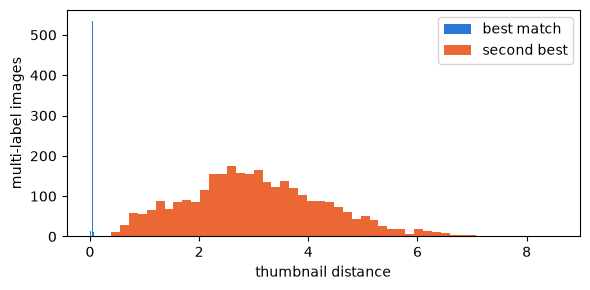

In [7]:
plt.figure(figsize=(6, 3))
plt.hist(best_dist, bins=50, color="#2a78d6", label="best match")
plt.hist(second_dist, bins=50, color="#eb6834", label="second best")
plt.xlabel("thumbnail distance")
plt.ylabel("multi-label images")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "matching_distances.png", dpi=200)
plt.show()

The five matches with the largest distance, which are the most likely to be wrong.
Top row: multi-label image. Bottom row: matched AID image and its scene.

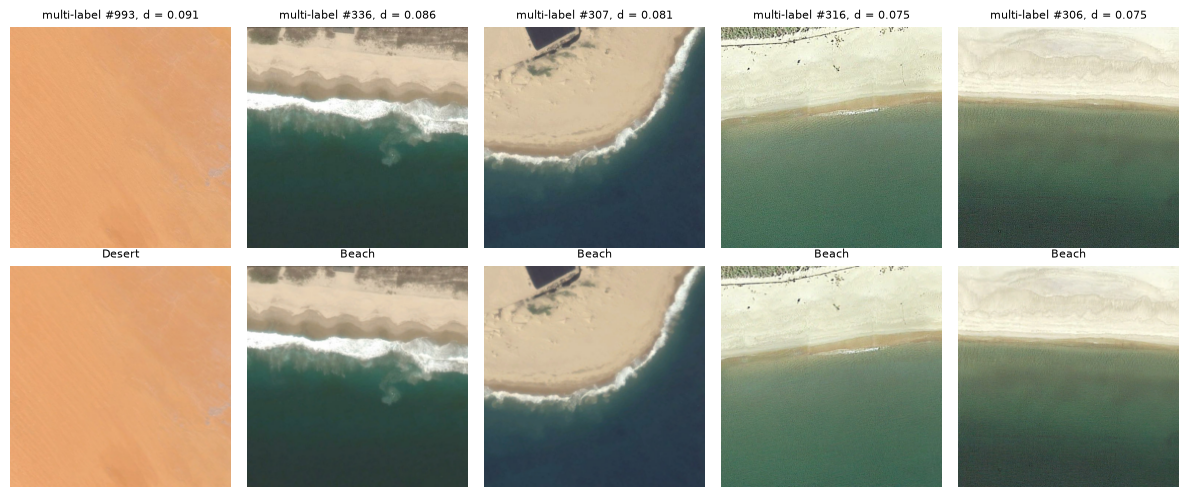

In [8]:
worst = np.argsort(best_dist)[-5:][::-1]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for col, i in enumerate(worst):
    axes[0, col].imshow(multilabel[int(i)]["image"])
    axes[0, col].set_title(f"multi-label #{i}, d = {best_dist[i]:.3f}", fontsize=8)
    axes[1, col].imshow(aid_images[best[i]])
    axes[1, col].set_title(aid["scene"][best[i]], fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

Pixel check: mean absolute difference between every multi-label image and its matched AID image at 224×224
(0–255 scale). A correct match gives a value close to 0; small non-zero values come from different JPEG encoding.

mean pixel difference: 1.016, largest: 2.174


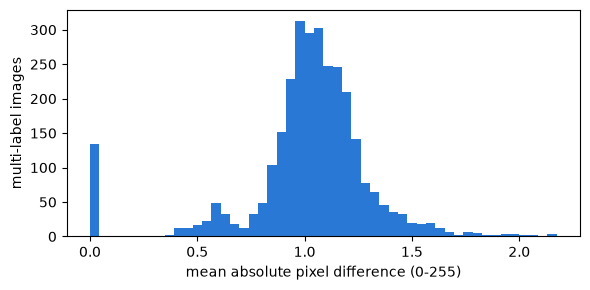

In [9]:
pixel_diff = np.array([np.abs(ml_images[i].astype(np.float32) - aid_images[best[i]]).mean() for i in range(len(best))])
print(f"mean pixel difference: {pixel_diff.mean():.3f}, largest: {pixel_diff.max():.3f}")

plt.figure(figsize=(6, 3))
plt.hist(pixel_diff, bins=50, color="#2a78d6")
plt.xlabel("mean absolute pixel difference (0-255)")
plt.ylabel("multi-label images")
plt.tight_layout()
plt.show()

## 6. Recovered scenes

How many multi-label images come from each scene.

min    100.0
max    100.0
Name: count, dtype: float64


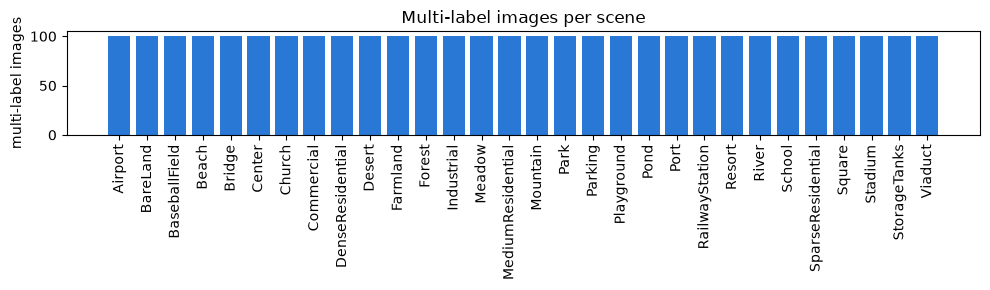

In [10]:
assert len(np.unique(best)) == len(best), "two multi-label images were matched to the same AID image"
ml_scene_counts = pd.Series(aid["scene"].to_numpy()[best]).value_counts().sort_index()
print(ml_scene_counts.describe()[["min", "max"]])

plt.figure(figsize=(10, 3))
plt.bar(ml_scene_counts.index, ml_scene_counts.values, color="#2a78d6")
plt.xticks(rotation=90)
plt.ylabel("multi-label images")
plt.title("Multi-label images per scene")
plt.tight_layout()
plt.show()

## 7. Labels and split

- *mobile home* is removed: it appears in only 2 of the 3,000 images, so its test AP would be undefined or decided by one image.
- Inside every scene the multi-label images are split into 72% train, 8% validation and 20% test.
- The other 7,000 AID images have no object labels. They get the split name `extra` and are used only to train the scene head.

In [11]:
object_names = [name for name in all_object_names if name != "mobile home"]
label_matrix = np.zeros((len(multilabel), len(all_object_names)), dtype=np.float32)
for i, labels in enumerate(multilabel["label"]):
    label_matrix[i, labels] = 1
keep = [all_object_names.index(name) for name in object_names]

meta = aid.copy()
meta["split"] = "extra"
for name in object_names:
    meta[name] = np.nan
meta.loc[best, object_names] = label_matrix[:, keep]

labeled = meta[object_names[0]].notna()
rng = np.random.default_rng(SPLIT_SEED)
for scene in scene_names:
    rows = rng.permutation(meta.index[(meta["scene"] == scene) & labeled])
    n_test, n_val = round(0.20 * len(rows)), round(0.08 * len(rows))
    meta.loc[rows[:n_test], "split"] = "test"
    meta.loc[rows[n_test:n_test + n_val], "split"] = "val"
    meta.loc[rows[n_test + n_val:], "split"] = "train"

print(meta["split"].value_counts())

split
extra    7000
train    2160
test      600
val       240
Name: count, dtype: int64


Leakage check: for every test image, the distance to the closest *other* AID image (training, validation or
scene-only). If this is far above the distance of a true match, no training image is a copy of a test image.

In [12]:
is_test = meta["split"].to_numpy()[best] == "test"
print(f"closest other AID image to any test image: {second_dist[is_test].min():.4f}")
print(f"largest distance of a true match:          {best_dist.max():.4f}")

closest other AID image to any test image: 0.4302
largest distance of a true match:          0.0911


## 8. Save the processed data

`images_224.npy` holds all 10,000 images (about 1.5 GB). `metadata.csv` has one row per image with its scene,
split and object labels (empty for `extra` images). The matching statistics are saved to `results/matching.json`.

In [13]:
np.save(PROCESSED_DIR / "images_224.npy", aid_images)
meta.to_csv(PROCESSED_DIR / "metadata.csv", index=False)
with open(PROCESSED_DIR / "labels.json", "w") as f:
    json.dump({"objects": object_names, "scenes": scene_names}, f, indent=2)

matching = {
    "multilabel_images": len(best),
    "distinct_matches": int(len(np.unique(best))),
    "largest_match_distance": float(best_dist.max()),
    "smallest_second_best_distance": float(second_dist.min()),
    "closest_other_image_to_a_test_image": float(second_dist[is_test].min()),
    "mean_pixel_difference": float(pixel_diff.mean()),
    "largest_pixel_difference": float(pixel_diff.max()),
    "images_per_scene": [int(ml_scene_counts.min()), int(ml_scene_counts.max())],
}
with open(RESULTS_DIR / "matching.json", "w") as f:
    json.dump(matching, f, indent=2)

Check: read the saved files back and show random training images with their scene and object labels.

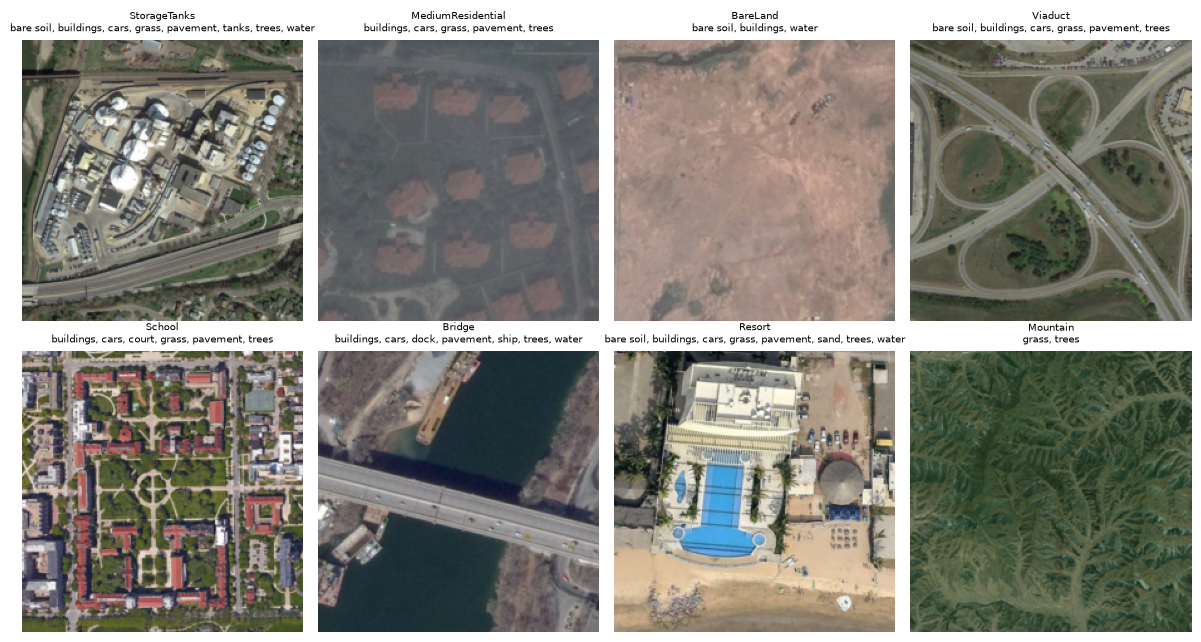

In [14]:
data = load_data()
rng = np.random.default_rng(1)
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for ax, i in zip(axes.ravel(), rng.choice(split_indices(data, "train"), 8, replace=False)):
    ax.imshow(data["images"][i])
    labels = [name for name, value in zip(data["object_names"], data["objects"][i]) if value]
    ax.set_title(data["scene_names"][data["scenes"][i]] + "\n" + ", ".join(labels), fontsize=7)
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "sample_images.png", dpi=200)
plt.show()

## 9. Dataset statistics

All statistics below use the training split only.

### 9.1 Label frequency

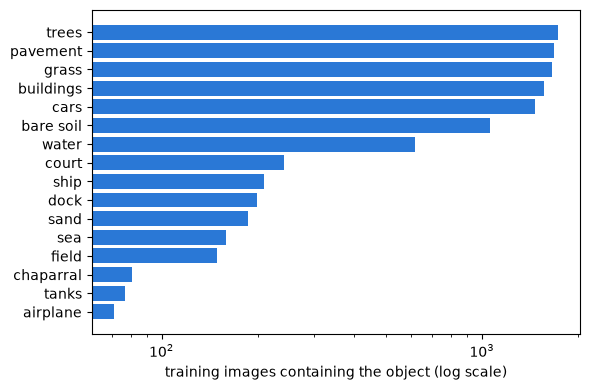

airplane       71
tanks          77
chaparral      81
field         149
sea           159
sand          186
dock          198
ship          209
court         241
water         620
bare soil    1057
cars         1467
buildings    1557
grass        1652
pavement     1676
trees        1725


In [15]:
train = split_indices(data, "train")
train_objects = data["objects"][train]
frequency = pd.Series(train_objects.sum(0), index=data["object_names"]).sort_values()

plt.figure(figsize=(6, 4))
plt.barh(frequency.index, frequency.values, color="#2a78d6")
plt.xscale("log")
plt.xlabel("training images containing the object (log scale)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "label_frequency.png", dpi=200)
plt.show()
print(frequency.astype(int).to_string())

### 9.2 Label co-occurrence

Cell (row *i*, column *j*) is P(*j* present | *i* present).

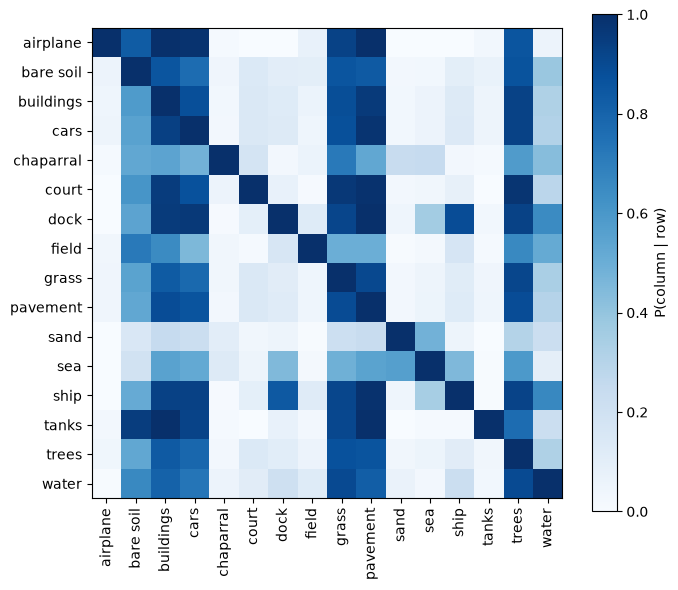

In [16]:
both = train_objects.T @ train_objects
cooccurrence = both / np.maximum(np.diag(both)[:, None], 1)

plt.figure(figsize=(7, 6))
plt.imshow(cooccurrence, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="P(column | row)")
plt.xticks(range(len(data["object_names"])), data["object_names"], rotation=90)
plt.yticks(range(len(data["object_names"])), data["object_names"])
plt.tight_layout()
plt.savefig(FIGURE_DIR / "cooccurrence.png", dpi=200)
plt.show()

### 9.3 Objects per scene

Cell (scene *s*, object *o*) is the fraction of training images of scene *s* that contain object *o*, P(*o* | *s*).
This table is the scene prior used by model B2.

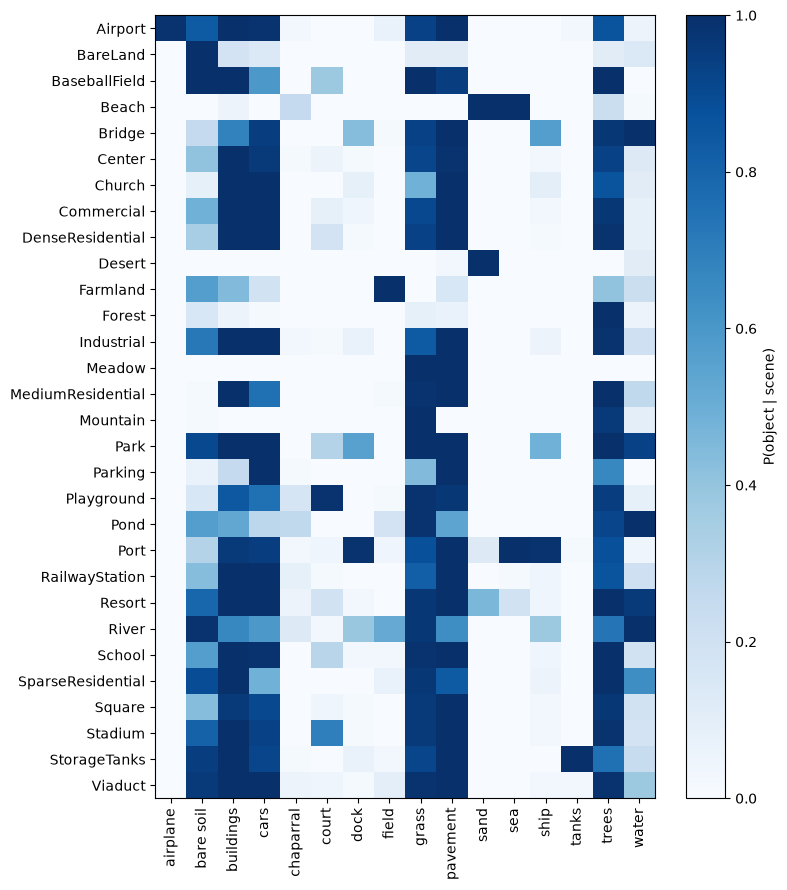

In [17]:
table = scene_object_table(data, smoothing=0)

plt.figure(figsize=(8, 9))
plt.imshow(table, cmap="Blues", vmin=0, vmax=1, aspect="auto")
plt.colorbar(label="P(object | scene)")
plt.xticks(range(len(data["object_names"])), data["object_names"], rotation=90)
plt.yticks(range(len(data["scene_names"])), data["scene_names"])
plt.tight_layout()
plt.savefig(FIGURE_DIR / "scene_object_table.png", dpi=200)
plt.show()

### 9.4 Scene-specific labels

For each object, the share of its positive training images that come from its three most common scenes.
Following the proposal, an object is called *scene-specific* if this share is above 50%.

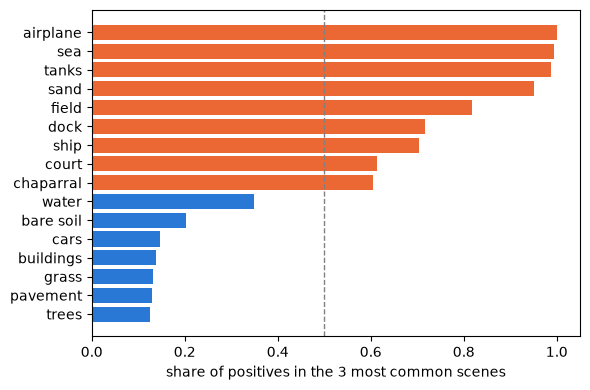

scene-specific labels: ['chaparral', 'court', 'ship', 'dock', 'field', 'sand', 'tanks', 'sea', 'airplane']


In [18]:
positives_per_scene = np.zeros((len(data["scene_names"]), len(data["object_names"])))
for i in train:
    positives_per_scene[data["scenes"][i]] += data["objects"][i]
top3_share = np.sort(positives_per_scene, axis=0)[-3:].sum(0) / np.maximum(positives_per_scene.sum(0), 1)
top3_share = pd.Series(top3_share, index=data["object_names"]).sort_values()
scene_specific = list(top3_share.index[top3_share > 0.5])

plt.figure(figsize=(6, 4))
colors = ["#eb6834" if name in scene_specific else "#2a78d6" for name in top3_share.index]
plt.barh(top3_share.index, top3_share.values, color=colors)
plt.axvline(0.5, color="gray", linestyle="--", linewidth=1)
plt.xlabel("share of positives in the 3 most common scenes")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "scene_specific_labels.png", dpi=200)
plt.show()

print("scene-specific labels:", scene_specific)
with open(RESULTS_DIR / "scene_specific_labels.json", "w") as f:
    json.dump(scene_specific, f, indent=2)

## 10. How much does the scene alone tell us?

Two reference predictors that need no training, evaluated on the test split:

- **label frequency**: every test image gets the same score per object, its training frequency (chance level for mAP);
- **true-scene prior**: every test image gets P(*o* | *s*) of its true scene. This uses the test scene label,
  so it is not a valid model, only an estimate of how much information the scene label carries about the objects.

In [19]:
test = split_indices(data, "test")
truth = data["objects"][test]
reference = {
    "label frequency": compute_metrics(np.tile(train_objects.mean(0), (len(test), 1)), truth),
    "true-scene prior": compute_metrics(table[data["scenes"][test]], truth),
}
columns = ["mAP", "example_F1", "macro_F1"]
print(pd.DataFrame(reference).T[columns].astype(float).round(4))

with open(RESULTS_DIR / "reference_predictors.json", "w") as f:
    json.dump(reference, f, indent=2)

                     mAP  example_F1  macro_F1
label frequency   0.3228      0.6999    0.2676
true-scene prior  0.8679      0.9036    0.8062
